<div align="center">

# CA3 ML 🚀

**Machine learning computer assignment**

👤 **Author:** Sadegh Samadi  |  📅 **Date:** 2025-5-17  |  📄 **SSID:** 810102588

</div>


## 🔖 Table of Contents
1. [Libraries](#libraries)
2. [Load and Preprocess Data](#load-and-preprocess-data)
3. [Handling Missing Values](#handle-missing-values)
4. [Data Visualization](#data-visualization)
5. [Create Label](#create-label)
6. [Train Test Split](#train-test-split)
7. [Normalization](#normalization)
8. [Model Evaluation](#model-evaluation)
9. [Model Training](#model-training)


## ❓ Table of Q&A
1. [Missing Values Methods](#1-deletion-methods)
2. [Normalizing Methods](#normalization)
3. [Model Evaluation Functions](#model-evaluation)
4. [Most Important Features in Decision Tree](#-what-are-the-most-important-feature-in-the-decision-tree)
5. [Comparasion Between Custom and Sklearn Model](#-comparasion-between-my-model-and-sklearn-model)



---
## Libraries

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, MaxAbsScaler, LabelEncoder
import numpy as np
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
from IPython.display import display, Markdown
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

> ### ⚠️ Also, I’ve installed **tabulate** to display pandas DataFrames more cleanly.



---

## Load and Preprocess Data

In [8]:
df = pd.read_csv('Grades.csv')
non_numeric_maps = {
    'sex':{'F': 1, 'M': 0},
    'address':{'U': 1, 'R': 0},
    'university':{'PR': 1, 'CM': 0},
    'universitySupport':{'yes': 1, 'no': 0},
    'paid':{'yes': 1, 'no': 0},
    'higher':{'yes': 1, 'no': 0},
    'internet':{'yes': 1, 'no': 0},
    'romantic':{'yes': 1, 'no': 0},    
    'motherJob': {
        'other':  0,
        'health':   1,
        'at_home':    2,
        'services': 3,
        'teacher':  4
    },
    'fatherJob': {
        'other':  0,
        'health':   1,
        'at_home':    2,
        'services': 3,
        'teacher':  4
    },
    'reason': {
        'other':     0,
        'home':       1,
        'course':      2,
        'reputation': 3
    }
}
for column, mapping in non_numeric_maps.items():
    df[column] = df[column].map(mapping)


### ❓ **What are the methods to handling missing values?**

>#### **1. Deletion Methods**
>- *Row or column deletion*
>#### **2. Simple Imputation**
>- *Mean / Median / Mode Imputation*
>#### **3. K-Nearest Neighbors imputation**
>#### **4. Model-based imputation**
>- *Train a regression or classification model to predict the missing feature*
>#### **5. probabilistic imputation**
>- *Probabilistic imputation replaces missing values by randomly sampling from the observed data's distribution, preserving its inherent variability*







---

## Handle missing values

In [9]:
missing_columns = ['motherJob', 'fatherJob', 'reason']
for column in missing_columns:
    count_of_other = (df[column] == 2).sum()
    percentage = count_of_other / len(df) * 100
    print(f"{column}: {count_of_other} over {len(df)} are 'other'({percentage:.1f}%)")

motherJob: 60 over 397 are 'other'(15.1%)
fatherJob: 20 over 397 are 'other'(5.0%)
reason: 146 over 397 are 'other'(36.8%)


> #### 💡**Note**: *According to the results, we can drop the motherJob and fatherJob columns because they contain almost entirely missing values and are not important features. We can impute the missing values in reason by inferring from other features—for example, assigning “home” when travelTime indicates a home value. Since only 10% of the reason entries are missing, it would be preferable to use simple imputation or probabilistic imputation.*

In [10]:
df = df.drop(columns = ['motherJob', 'fatherJob'])
missing_idx = df[df['reason'] == 0].index
not_missing = df.loc[df['reason'] != 0, 'reason']
probs = not_missing.value_counts(normalize = True)
imputed_values = np.random.choice(probs.index, size = len(missing_idx), p = probs.values)
df.loc[missing_idx, 'reason'] = imputed_values


---

## Data Visualization

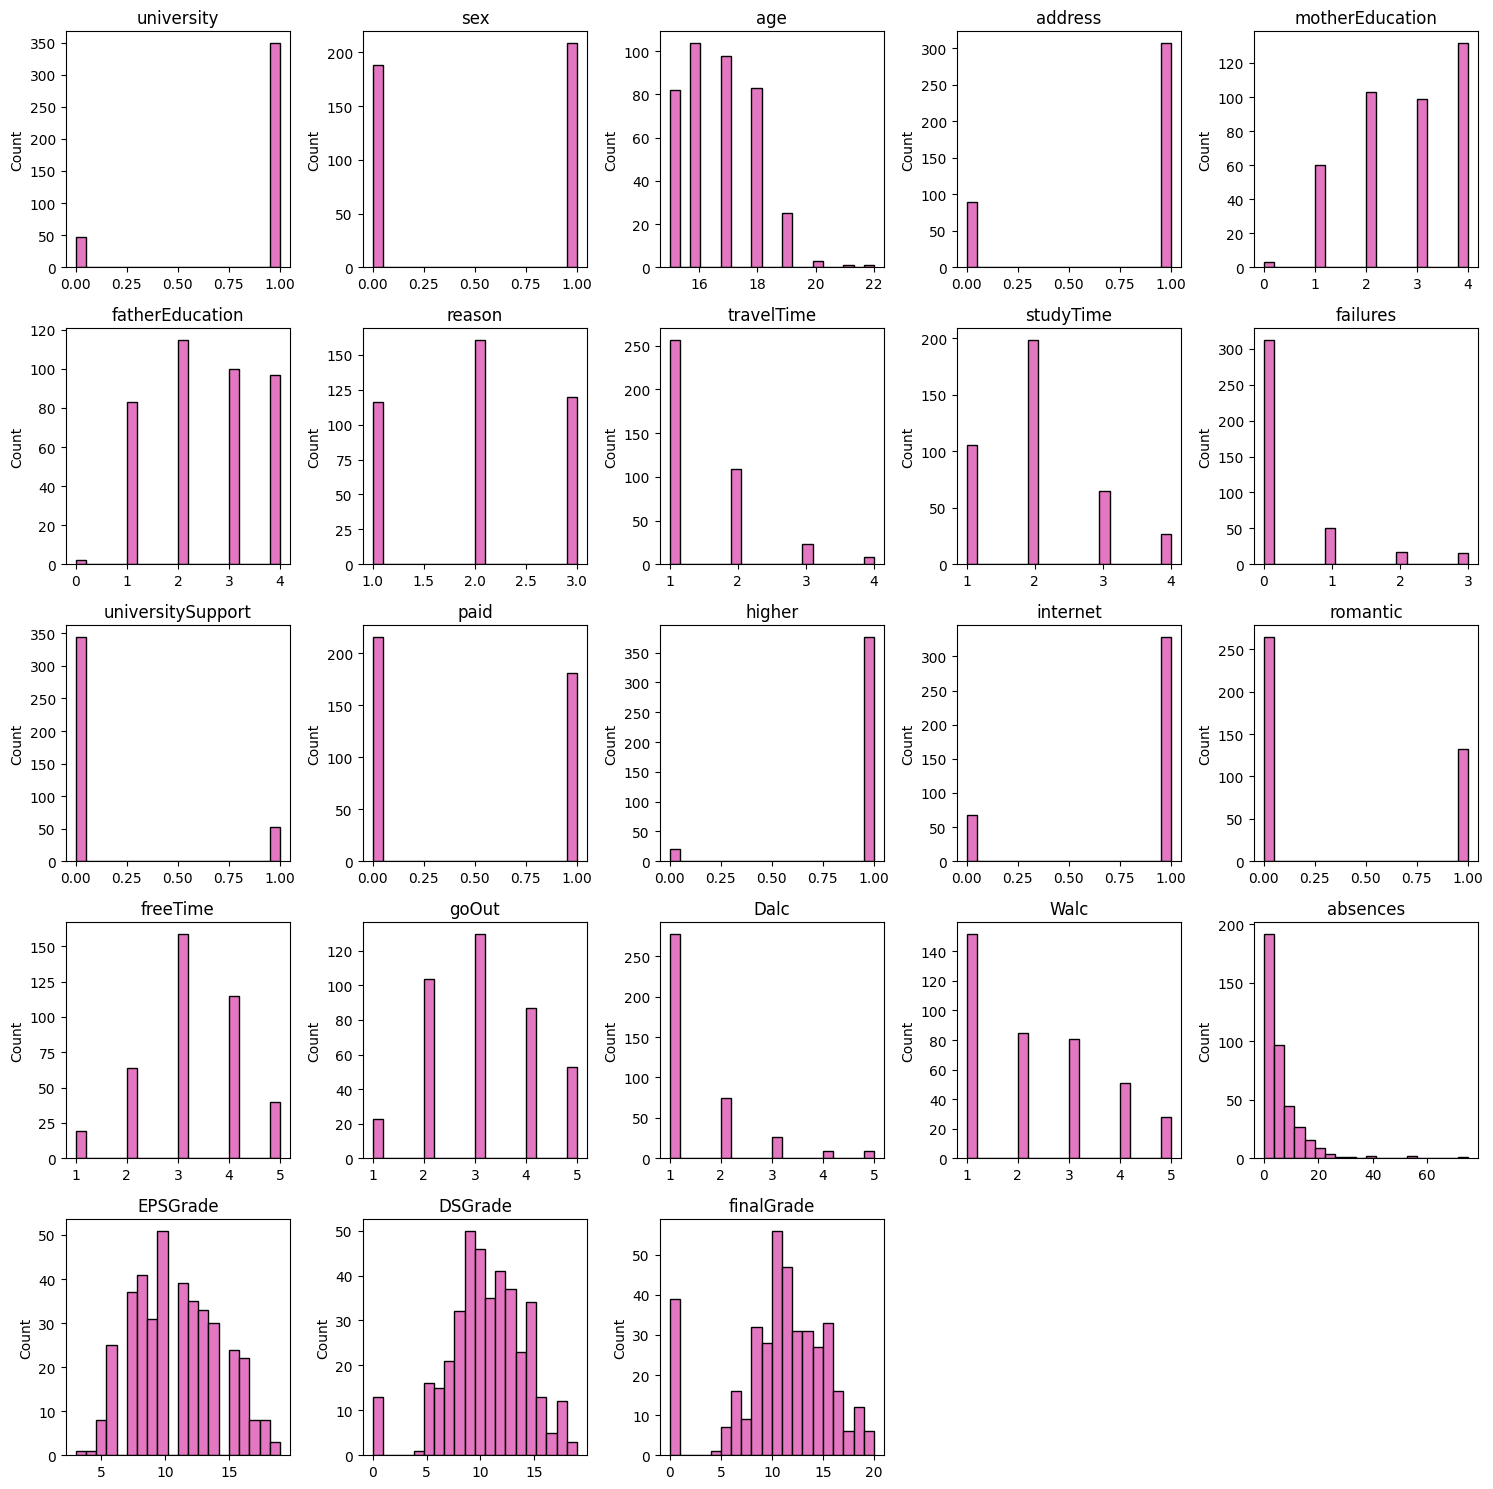

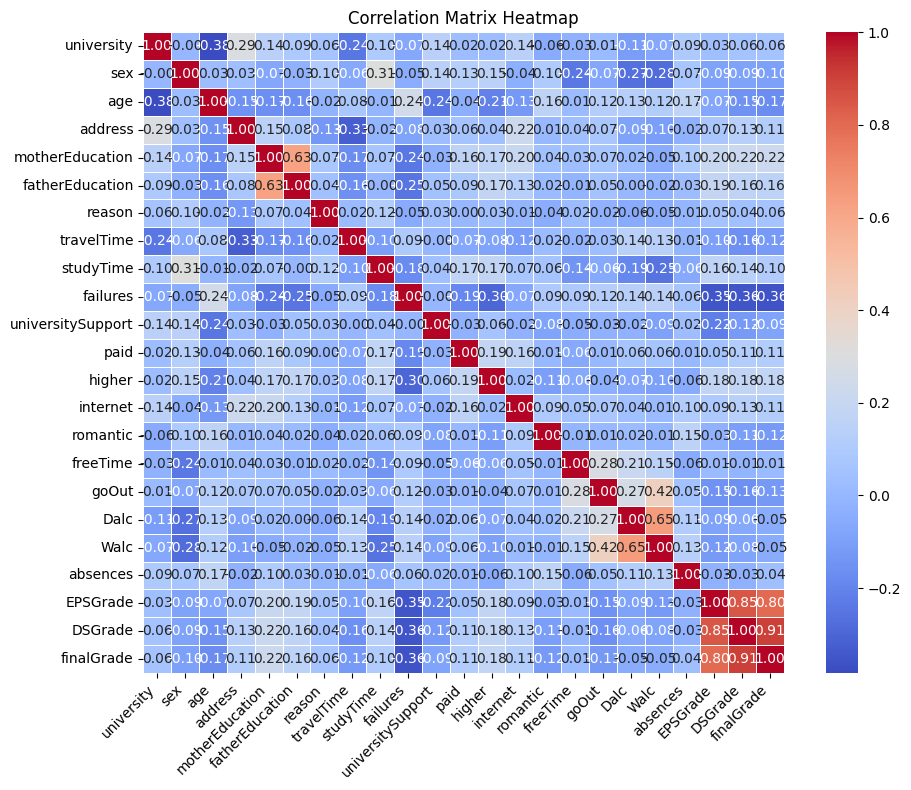

In [11]:
def plot_grid(draw_function, cols, num_col = 3, figsize = (15, 4)):
    n = len(cols)
    nrows = math.ceil(n / num_col)
    fig, axes = plt.subplots(nrows, num_col, figsize = (figsize[0], figsize[1] * nrows))
    axes = axes.flatten()
    for ax, col in zip(axes, cols):
        draw_function(ax, col)
    for ax in axes[n:]:
        ax.set_visible(False)
    plt.tight_layout()
    plt.show()

def draw_hist(ax, col):
    ax.hist(df[col].dropna(), bins = 20, color = 'C6', edgecolor = 'k')
    ax.set_title(f'{col}')
    ax.set_xlabel('')
    ax.set_ylabel('Count')

def draw_count(ax, col):
    sns.countplot(x = col, hue = col, data = df, palette = 'pastel', ax = ax, legend = False)
    ax.set_title(f'Count of {col}')
    ax.set_xlabel('')
    ax.set_ylabel('Count')
    for label in ax.get_xticklabels():
        label.set_rotation(45)
        label.set_ha('right')

def draw_heatmap(df, figlen = (10, 8)):
    corr = df.corr()
    plt.figure(figsize = figlen)
    sns.heatmap(corr, annot = True, fmt = ".2f", cmap = "coolwarm", linewidths = 0.5, square = True)
    plt.title('Correlation Matrix Heatmap')
    plt.xticks(rotation = 45, ha = 'right')
    plt.yticks(rotation = 0)
    plt.tight_layout()
    plt.show()

plot_grid(draw_hist, df.columns, num_col = 5, figsize = (15, 3))
draw_heatmap(df)



---

## Create Label

In [12]:
def create_label(grade):
    if grade < 10: 
        return 3
    elif grade < 14: 
        return 2
    elif grade < 17: 
        return 1
    return 0

df['Label'] = df['finalGrade'].apply(create_label)
features = df.drop(['finalGrade','Label'], axis = 1)
labels = df['Label']


---

## Train Test Split

In [13]:
feature_train, feature_test, label_train, label_test = train_test_split(features, labels, test_size = 0.2, random_state = 20, stratify = labels)


---

## Normalization

### ❓ **What are the methods to normalizing?**

>#### **1. Min-Max scaling**  
> $$
> x' = \frac{x - x_{\min}}{x_{\max} - x_{\min}}
> $$
>#### **2. Z-Score Standardization (Standard Scaling)**
> $$
> x' = \frac{x - \mu}{\sigma}
> $$
>#### **3. Robust Scaling**
> $$
> x' = \frac{x - \mathrm{median}}{\mathrm{IQR}}
> $$
>- where IQR = 75th percentile − 25th percentile. 
>#### **4. Max-Absolute Scaling**
>$$
>x' = \frac{x}{\lvert x_{\max} \rvert}
>$$


In [14]:
scalers = {
    'None': None,
    'StandardScaler': StandardScaler(),
    'MinMaxScaler':   MinMaxScaler(),
    'RobustScaler':   RobustScaler(),
    'MaxAbsScaler':   MaxAbsScaler()
}
def train_test_scaled_split(features, labels, random_state):
    scalers = {
        'None': None,
        'StandardScaler': StandardScaler(),
        'MinMaxScaler':   MinMaxScaler(),
        'RobustScaler':   RobustScaler(),
        'MaxAbsScaler':   MaxAbsScaler()
    }
    feature_train, feature_test, label_train, label_test = train_test_split(features, labels, test_size = 0.2, random_state = random_state, stratify = labels, shuffle = True)
    feature_train_scaled = []
    feature_test_scaled = []
    for name, scaler in scalers.items():
        if scaler is not None:
            train_scaled = pd.DataFrame(scaler.fit_transform(feature_train), columns = feature_train.columns, index = feature_train.index)
            test_scaled = pd.DataFrame(scaler.transform(feature_test), columns = feature_test.columns, index = feature_test.index)
        else:
            train_scaled = feature_train.copy()
            test_scaled = feature_test.copy()
        feature_train_scaled.append(train_scaled)
        feature_test_scaled.append(test_scaled)
    return feature_train_scaled, feature_test_scaled, label_train, label_test

> #### 💡**Note**: *We applied all of the scaling methods described above to compare their effects and determine which technique is most suitable for each model.*


--- 

## Model Evaluation

### ❓ **What are the evaluation functions for models?**

>#### **1. Accuracy**  
> $$
> \text{Accuracy} \;=\; \frac{TP + TN}{TP + TN + FP + FN}
> $$
>#### **2. confusion Matrix**
>|               | **Predicted Positive** | **Predicted Negative** |
>|---------------|------------------------|------------------------|
>| **Actual Positive** | True Positive (TP)        | False Negative (FN)       |
>| **Actual Negative** | False Positive (FP)       | True Negative (TN)        |
>#### **3. Precision**
> $$
> \text{Precision} \;=\; \frac{TP}{TP + FP}
> $$
>- Out of all predicted positives, the fraction that are true positives. 
>#### **4. Recall**
>$$
>\text{Recall} \;=\; \frac{TP}{TP + FN}
>$$
>- Out of all actual positives, the fraction that are correctly predicted.
>#### **5. F₁-Score**
>$$
>F_1 = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}
>$$
>- Harmonic mean of precision and recall.
>#### **6.1. Macro-averaging**
>$$
>\text{Macro-Metric} = \frac{1}{M}\sum_{i=1}^M \text{Metric}_i
>$$
>#### **6.2. Micro-averaging**
>$$
> \text{Micro-Precision}= \frac{\sum_i TP_i}{\sum_i (TP_i + FP_i)}, \quad\text{Micro-Recall} = \frac{\sum_i TP_i}{\sum_i (TP_i + FN_i)}
>$$
>#### **6.3. Weighted-averaging**
>- *Weighs each class by its support (number of true instances):*
>$$
> \text{Weighted-Metric} = \frac{\sum_{i=1}^M \bigl(\text{support}_i \times \text{Metric}_i\bigr)}{\sum_{i=1}^M \text{support}_i}
>$$


In [15]:

def display_markdown_table(df, title=None):
    md = df.to_markdown(index=False)
    if title:
        display(Markdown(f"### {title}\n\n{md}"))
    else:
        display(Markdown(md))


def evaluate_predictions(label_test, predictions, label_order):
    result = []
    n = len(predictions)
    fig, axes = plt.subplots(1, n, figsize=(5 * n, 4))

    for ax, (name, y_pred) in zip(axes, predictions.items()):
        acc = accuracy_score(label_test, y_pred)

        p_macro   = precision_score(label_test, y_pred, average = 'macro', zero_division = 0)
        p_micro   = precision_score(label_test, y_pred, average = 'micro', zero_division = 0)
        p_weight  = precision_score(label_test, y_pred, average = 'weighted', zero_division = 0)
        
        r_macro   = recall_score(label_test, y_pred, average = 'macro', zero_division = 0)
        r_micro   = recall_score(label_test, y_pred, average = 'micro', zero_division = 0)
        r_weight  = recall_score(label_test, y_pred, average = 'weighted', zero_division = 0)
        
        f1_macro  = f1_score(label_test, y_pred, average = 'macro', zero_division = 0)
        f1_micro  = f1_score(label_test, y_pred, average = 'micro', zero_division = 0)
        f1_weight = f1_score(label_test, y_pred, average = 'weighted', zero_division = 0)
        
        result.append({
            'Name': name,
            'Accuracy': acc,
            'P_macro': p_macro,  'R_macro': r_macro,  'F1_macro': f1_macro,
            'P_micro': p_micro,  'R_micro': r_micro,  'F1_micro': f1_micro,
            'P_weight': p_weight,'R_weight': r_weight,'F1_weight': f1_weight
        })

        cm = confusion_matrix(label_test, y_pred, labels = label_order)
        sns.heatmap(cm, annot = True, fmt = 'd', cmap = 'Blues', ax = ax, xticklabels = label_order, yticklabels = label_order, cbar = False)
        ax.set_title(name)
        ax.set_xlabel('Predicted')
        ax.set_ylabel('Actual')
        
    plt.tight_layout()
    plt.show()
    results_df = pd.DataFrame(result)
    display_markdown_table(results_df)



--- 

## Model Training

- ### Naive Bayes Model

---

## **Evaluating feature set:**  `DSGrade`


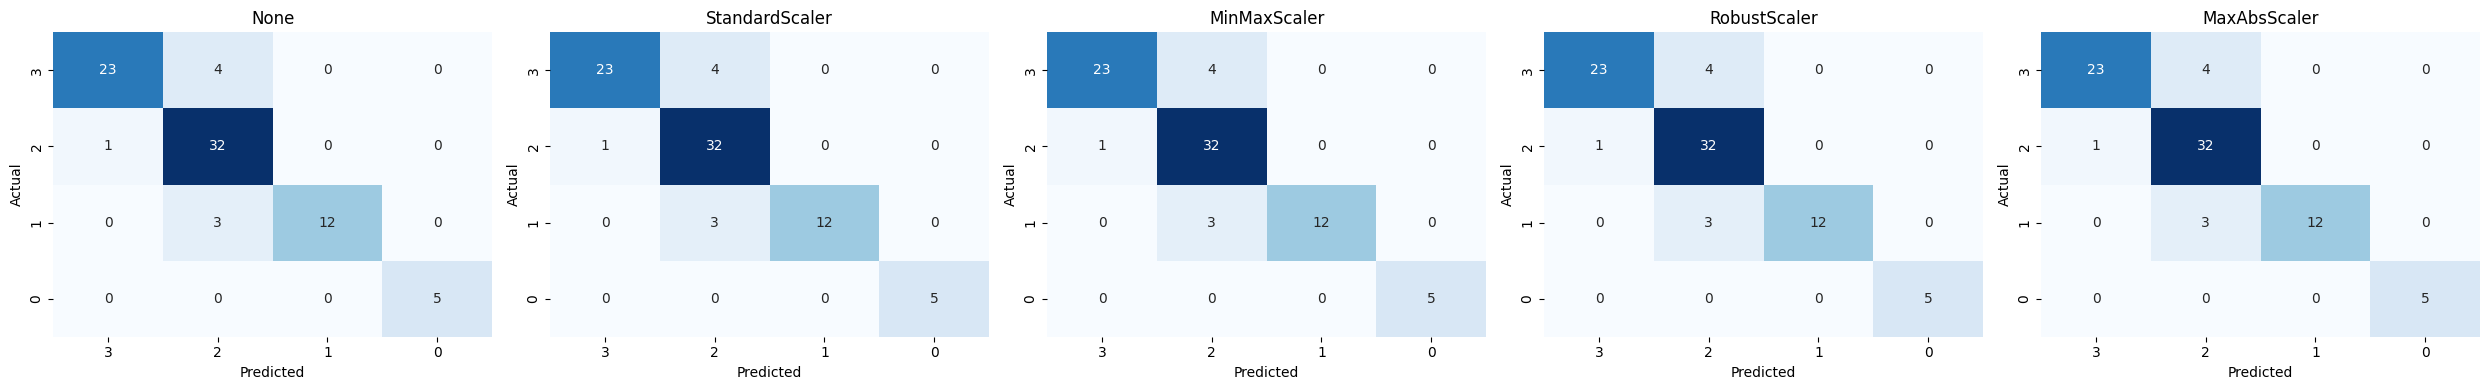

| Name           |   Accuracy |   P_macro |   R_macro |   F1_macro |   P_micro |   R_micro |   F1_micro |   P_weight |   R_weight |   F1_weight |
|:---------------|-----------:|----------:|----------:|-----------:|----------:|----------:|-----------:|-----------:|-----------:|------------:|
| None           |        0.9 |  0.944712 |  0.905387 |   0.919935 |       0.9 |       0.9 |        0.9 |   0.911899 |        0.9 |    0.900245 |
| StandardScaler |        0.9 |  0.944712 |  0.905387 |   0.919935 |       0.9 |       0.9 |        0.9 |   0.911899 |        0.9 |    0.900245 |
| MinMaxScaler   |        0.9 |  0.944712 |  0.905387 |   0.919935 |       0.9 |       0.9 |        0.9 |   0.911899 |        0.9 |    0.900245 |
| RobustScaler   |        0.9 |  0.944712 |  0.905387 |   0.919935 |       0.9 |       0.9 |        0.9 |   0.911899 |        0.9 |    0.900245 |
| MaxAbsScaler   |        0.9 |  0.944712 |  0.905387 |   0.919935 |       0.9 |       0.9 |        0.9 |   0.911899 |        0.9 |    0.900245 |

---

## **Evaluating feature set:**  `university`, `sex`, `age`, `address`, `motherEducation`, `fatherEducation`, `reason`, `travelTime`, `studyTime`, `failures`, `universitySupport`, `paid`, `higher`, `internet`, `romantic`, `freeTime`, `goOut`, `Dalc`, `Walc`, `absences`, `EPSGrade`, `DSGrade`


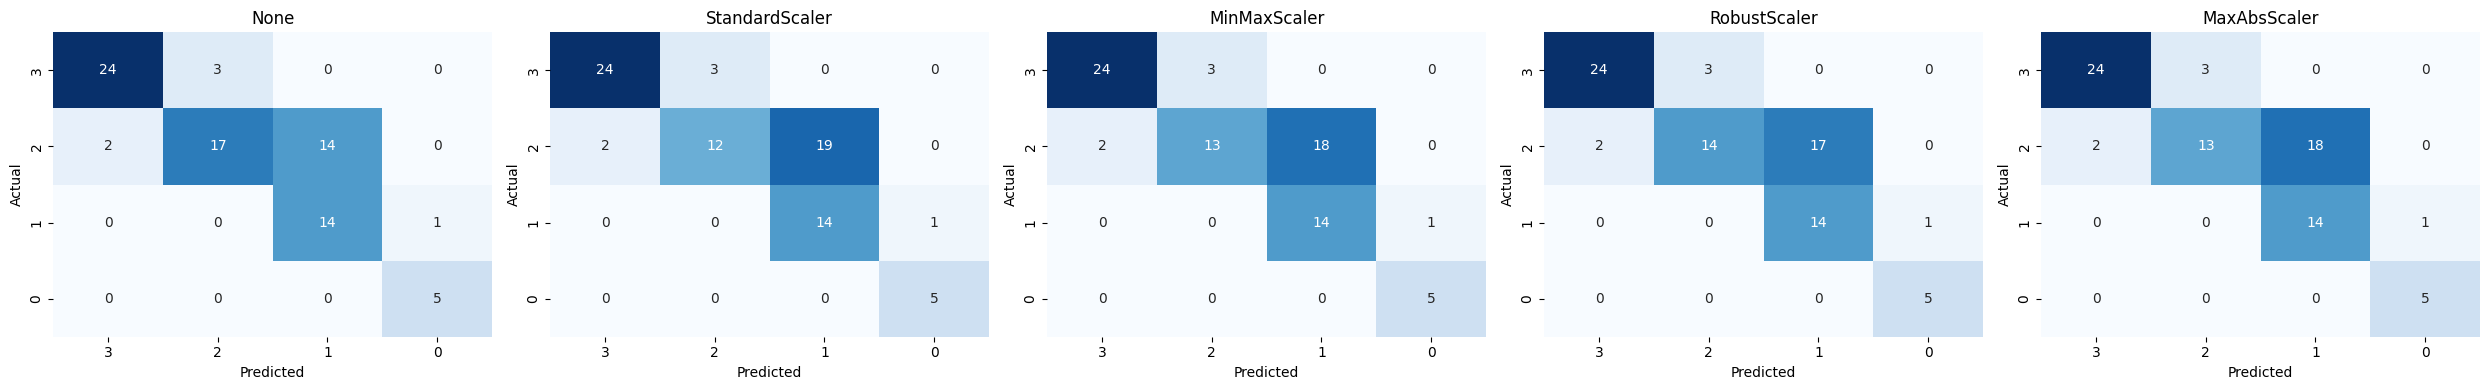

| Name           |   Accuracy |   P_macro |   R_macro |   F1_macro |   P_micro |   R_micro |   F1_micro |   P_weight |   R_weight |   F1_weight |
|:---------------|-----------:|----------:|----------:|-----------:|----------:|----------:|-----------:|-----------:|-----------:|------------:|
| None           |     0.75   |  0.776603 |  0.834343 |   0.776856 |    0.75   |    0.75   |     0.75   |   0.807997 |     0.75   |    0.749194 |
| StandardScaler |     0.6875 |  0.745163 |  0.796465 |   0.724521 |    0.6875 |    0.6875 |     0.6875 |   0.773167 |     0.6875 |    0.678104 |
| MinMaxScaler   |     0.7    |  0.751603 |  0.80404  |   0.735277 |    0.7    |    0.7    |     0.7    |   0.780809 |     0.7    |    0.693058 |
| RobustScaler   |     0.7125 |  0.757888 |  0.811616 |   0.745862 |    0.7125 |    0.7125 |     0.7125 |   0.788005 |     0.7125 |    0.707609 |
| MaxAbsScaler   |     0.7    |  0.751603 |  0.80404  |   0.735277 |    0.7    |    0.7    |     0.7    |   0.780809 |     0.7    |    0.693058 |

---

## **Evaluating feature set:**  `DSGrade`, `EPSGrade`


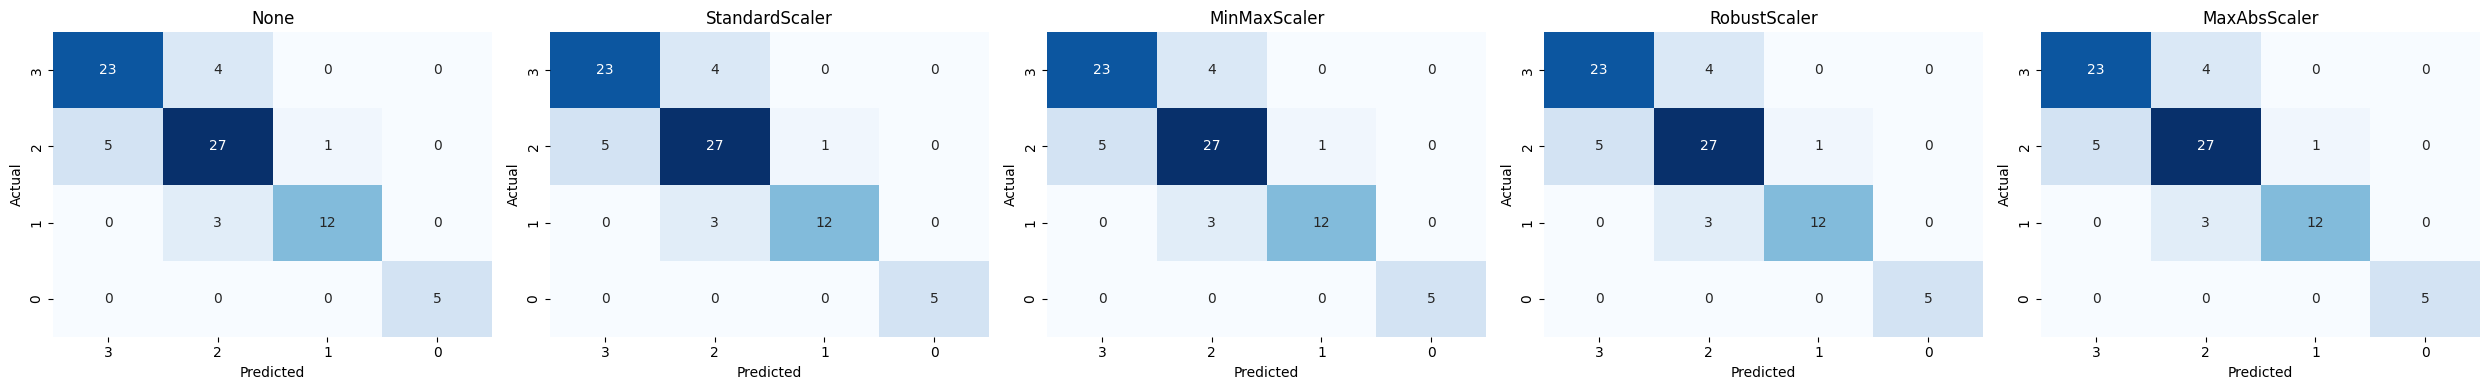

| Name           |   Accuracy |   P_macro |   R_macro |   F1_macro |   P_micro |   R_micro |   F1_micro |   P_weight |   R_weight |   F1_weight |
|:---------------|-----------:|----------:|----------:|-----------:|----------:|----------:|-----------:|-----------:|-----------:|------------:|
| None           |     0.8375 |  0.884656 |  0.867508 |   0.874869 |    0.8375 |    0.8375 |     0.8375 |   0.840383 |     0.8375 |     0.83795 |
| StandardScaler |     0.8375 |  0.884656 |  0.867508 |   0.874869 |    0.8375 |    0.8375 |     0.8375 |   0.840383 |     0.8375 |     0.83795 |
| MinMaxScaler   |     0.8375 |  0.884656 |  0.867508 |   0.874869 |    0.8375 |    0.8375 |     0.8375 |   0.840383 |     0.8375 |     0.83795 |
| RobustScaler   |     0.8375 |  0.884656 |  0.867508 |   0.874869 |    0.8375 |    0.8375 |     0.8375 |   0.840383 |     0.8375 |     0.83795 |
| MaxAbsScaler   |     0.8375 |  0.884656 |  0.867508 |   0.874869 |    0.8375 |    0.8375 |     0.8375 |   0.840383 |     0.8375 |     0.83795 |

In [16]:
NB_models = []
scaler_names = list(scalers.keys())
predictions = {}
selected_features_set = [['DSGrade'], list(features.columns), ['DSGrade', 'EPSGrade']]
for selected_features in selected_features_set:
    header = "**Evaluating feature set:**  " + ", ".join(f"`{f}`" for f in selected_features)
    display(Markdown(f"---\n\n## {header}\n"))
    feature_train_scaled, feature_test_scaled, label_train, label_test = train_test_scaled_split(features[selected_features], labels, random_state = 3)
    for i in range(len(scalers)): 
        NB_models.append(GaussianNB())
        NB_models[i].fit(feature_train_scaled[i], label_train)
        predictions[scaler_names[i]] = NB_models[i].predict(feature_test_scaled[i])
    evaluate_predictions(label_test, predictions, label_order = [3, 2, 1, 0])

> #### 💡**Note**: *According to the correlation heatmap, DSGrade and EPSGrade exhibit the strongest correlations with finalGrade. Therefore, by using only these two features, we can expect to achieve high accuracy and strong evaluation metrics.*

- ### Decision Tree

- #### HyperParameters
- **`criterion`**: Function to measure split quality (e.g. `"gini"`, `"entropy"`, `"log_loss"`).
- **`splitter`**: Strategy to choose the split at each node (`"best"` for optimal, `"random"` for faster/diverse splits).
- **`max_depth`**: Maximum depth of the tree (`None` for unlimited, or integers like `5`, `10`) to control overfitting.
- **`min_samples_split`**: Minimum number of samples required to split an internal node (e.g. `2`, `5`, `10`) to avoid tiny splits.
- **`min_samples_leaf`**: Minimum number of samples required at a leaf node (`1`, `2`, `5`) to ensure leaf stability.
- **`max_features`**: Number of features to consider when looking for the best split (`None`, `"sqrt"`, `"log2"`, or an integer).
- **`max_leaf_nodes`**: Maximum number of leaf nodes (`None`, or integers like `10`, `20`, `50`) to directly bound complexity.
- **`min_impurity_decrease`**: threshold for impurity decrease to split (`0.0`, `1e-3`, `1e-2`) to force only meaningful splits.
- **`ccp_alpha`**: Complexity parameter for minimal cost-complexity pruning (`0.0`, `1e-4`, `1e-3`) to prune weak branches.

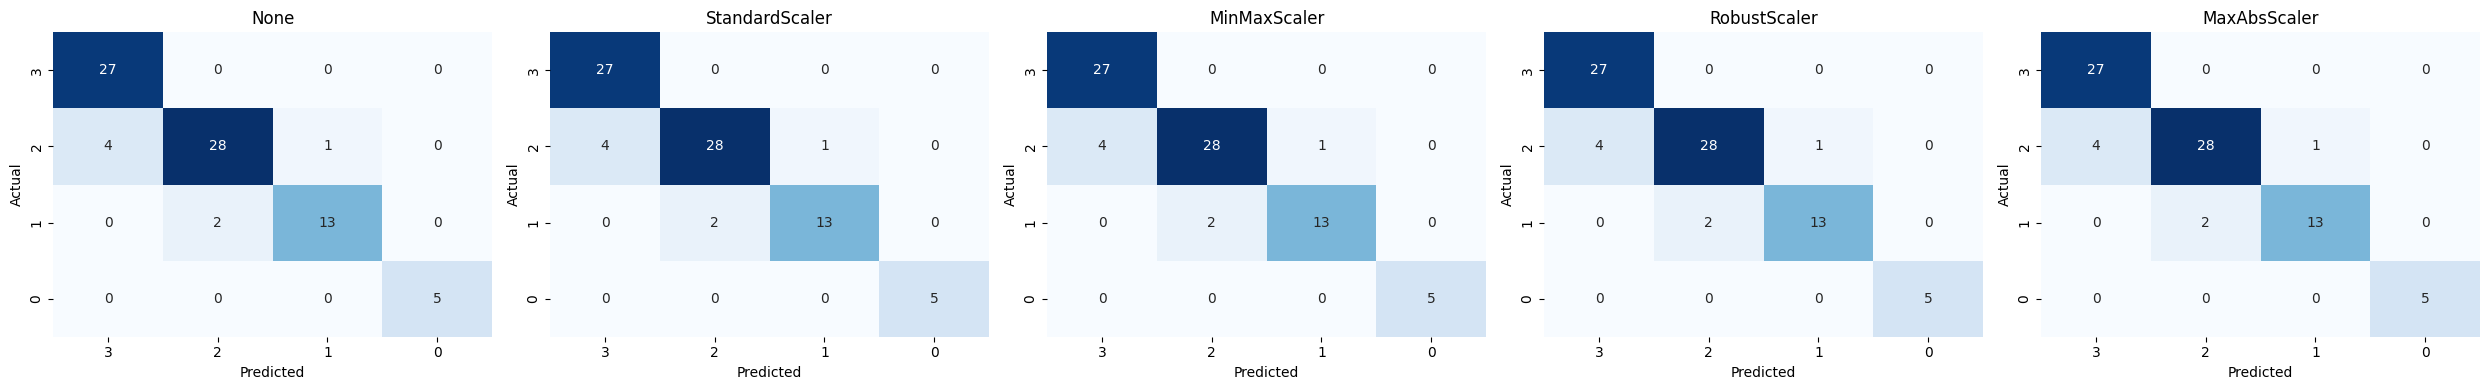

| Name           |   Accuracy |   P_macro |   R_macro |   F1_macro |   P_micro |   R_micro |   F1_micro |   P_weight |   R_weight |   F1_weight |
|:---------------|-----------:|----------:|----------:|-----------:|----------:|----------:|-----------:|-----------:|-----------:|------------:|
| None           |     0.9125 |  0.933218 |  0.928788 |   0.929119 |    0.9125 |    0.9125 |     0.9125 |   0.915559 |     0.9125 |    0.911494 |
| StandardScaler |     0.9125 |  0.933218 |  0.928788 |   0.929119 |    0.9125 |    0.9125 |     0.9125 |   0.915559 |     0.9125 |    0.911494 |
| MinMaxScaler   |     0.9125 |  0.933218 |  0.928788 |   0.929119 |    0.9125 |    0.9125 |     0.9125 |   0.915559 |     0.9125 |    0.911494 |
| RobustScaler   |     0.9125 |  0.933218 |  0.928788 |   0.929119 |    0.9125 |    0.9125 |     0.9125 |   0.915559 |     0.9125 |    0.911494 |
| MaxAbsScaler   |     0.9125 |  0.933218 |  0.928788 |   0.929119 |    0.9125 |    0.9125 |     0.9125 |   0.915559 |     0.9125 |    0.911494 |

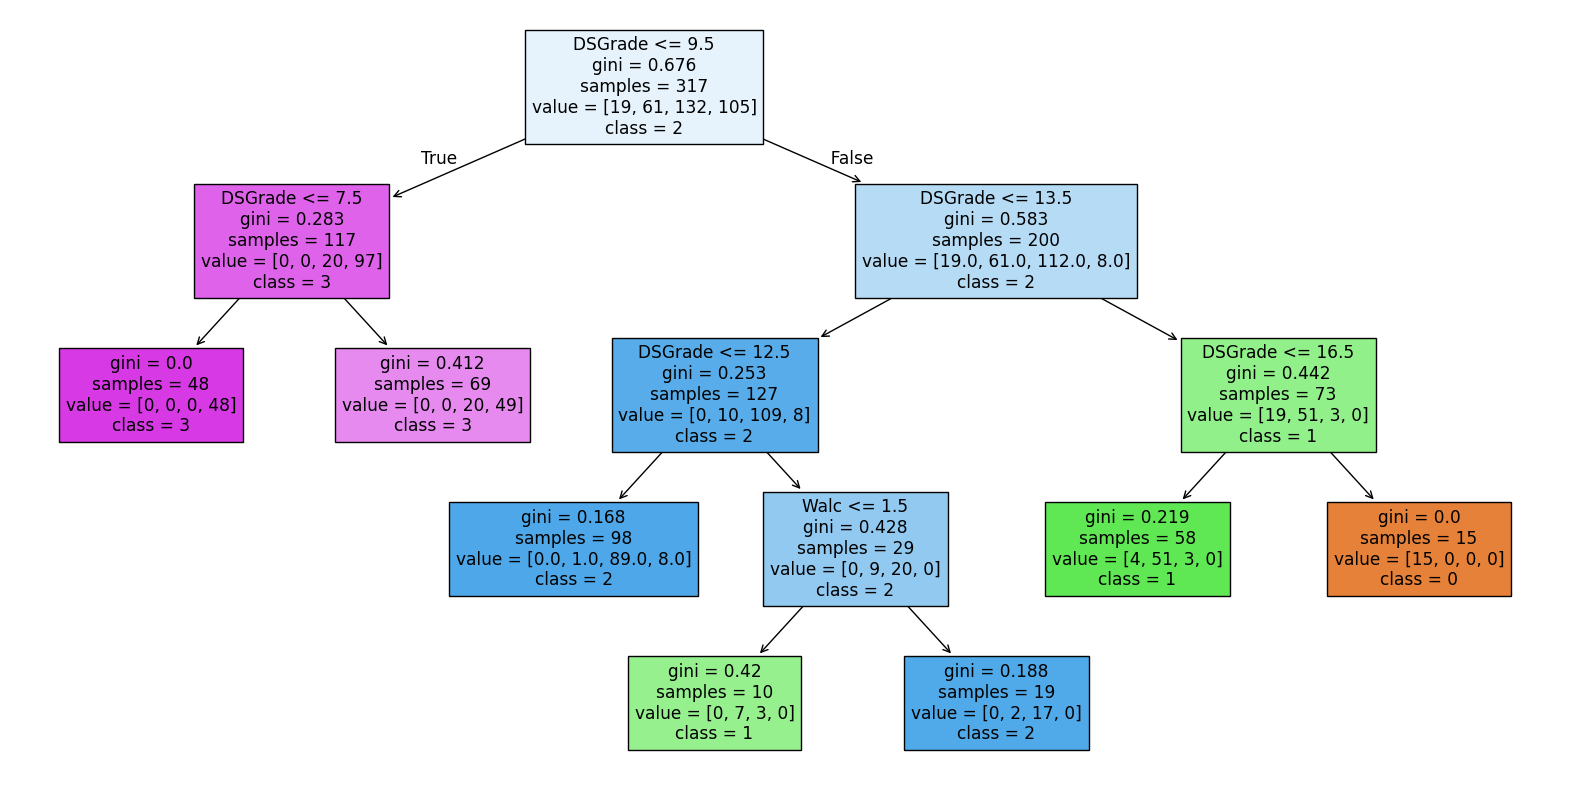

In [17]:
param_grid = {
    'criterion':           ['gini', 'entropy'],
    'max_depth':           [None, 5, 10, 20],
    'min_samples_split':   [2, 5, 10],
    'min_samples_leaf':    [1, 2, 5],
    'max_features':        [None, 'sqrt', 'log2'],
    'ccp_alpha':           [0.0, 1e-4, 1e-3, 1e-2]
}

DT_models = []
best_models = []
predictions = {}
feature_train_scaled, feature_test_scaled, label_train, label_test = train_test_scaled_split(features, labels, random_state = 3)
for i in range(len(scalers)): 
    DT_models.append(DecisionTreeClassifier(random_state = 398))
    grid = GridSearchCV(DT_models[i], param_grid, cv = 5, scoring = 'accuracy', n_jobs = -1)
    grid.fit(feature_train_scaled[i], label_train)
    best_models.append(grid.best_estimator_)
    predictions[scaler_names[i]] = best_models[i].predict(feature_test_scaled[i])
evaluate_predictions(label_test, predictions, label_order = [3, 2, 1, 0])

plt.figure(figsize = (20, 10))
plot_tree(best_models[0], feature_names = features.columns, class_names = [str(c) for c in best_models[0].classes_], filled = True)
plt.show()

> #### 💡**Note**: *As we can see in the table above, scalers do not affect Decision Trees. Therefore, we only plot the results for one of them.*


### ❓ **What are the most important feature in the Decision tree?**

>#### *According to the tree structure and the way it is constructed, features closer to the root are the most important, as they are selected based on comparisons with all other features. Therefore, as we move deeper into the decision tree, the features tend to become less important because the higher-level (closer to root) features have already captured the most significant information.*
>#### *As we can see, DSGrade is the most strongly correlated with finalGrade, so it is expected that the most important feature would be DSGrade. Following that, the next most important feature is Walc, which clearly affects students' academic performance and concentration.*



- ### Random Forest

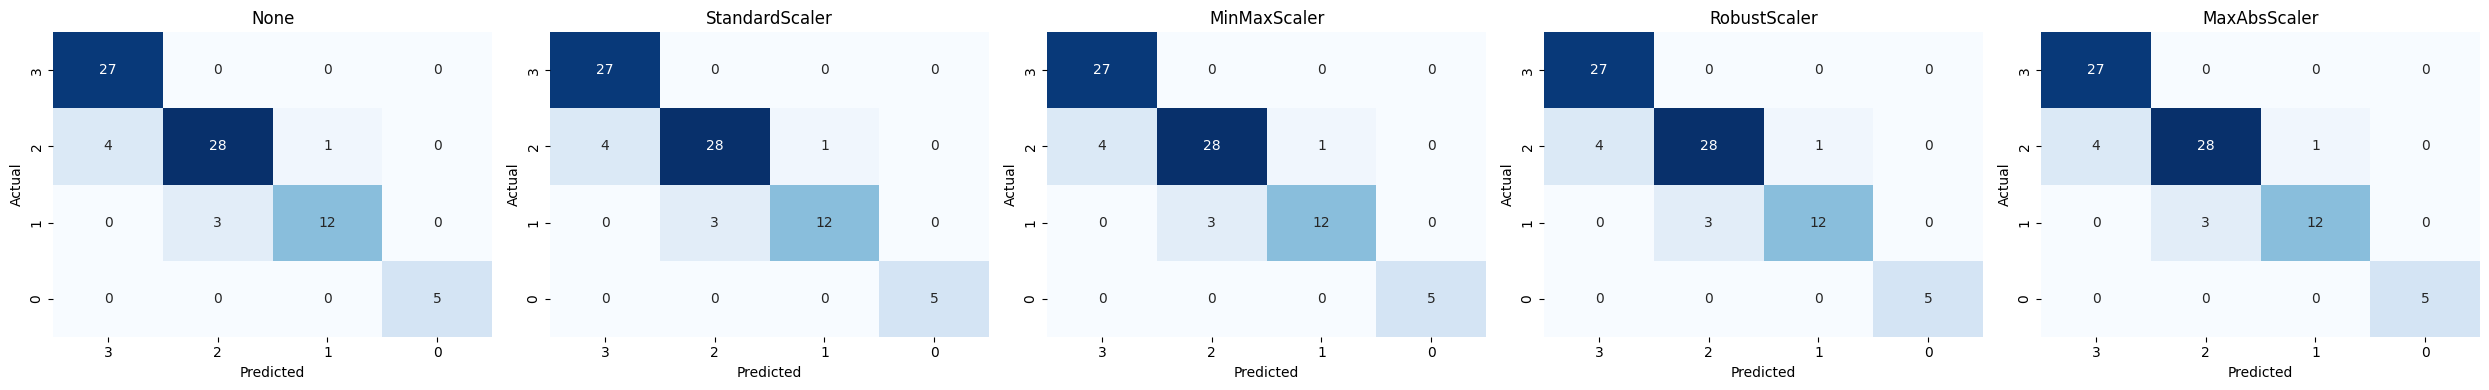

| Name           |   Accuracy |   P_macro |   R_macro |   F1_macro |   P_micro |   R_micro |   F1_micro |   P_weight |   R_weight |   F1_weight |
|:---------------|-----------:|----------:|----------:|-----------:|----------:|----------:|-----------:|-----------:|-----------:|------------:|
| None           |        0.9 |  0.924318 |  0.912121 |   0.915794 |       0.9 |       0.9 |        0.9 |   0.902109 |        0.9 |    0.898376 |
| StandardScaler |        0.9 |  0.924318 |  0.912121 |   0.915794 |       0.9 |       0.9 |        0.9 |   0.902109 |        0.9 |    0.898376 |
| MinMaxScaler   |        0.9 |  0.924318 |  0.912121 |   0.915794 |       0.9 |       0.9 |        0.9 |   0.902109 |        0.9 |    0.898376 |
| RobustScaler   |        0.9 |  0.924318 |  0.912121 |   0.915794 |       0.9 |       0.9 |        0.9 |   0.902109 |        0.9 |    0.898376 |
| MaxAbsScaler   |        0.9 |  0.924318 |  0.912121 |   0.915794 |       0.9 |       0.9 |        0.9 |   0.902109 |        0.9 |    0.898376 |

In [18]:
param_dist = {
    'n_estimators':      [50, 100, 200, 500],
    'criterion':         ['gini', 'entropy'],
    'max_depth':         [None, 5, 10, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf':  [1, 2, 5],
    'max_features':      [None, 'sqrt', 'log2'],
    'bootstrap':         [True, False],
    'ccp_alpha':         [0.0, 1e-4, 1e-3, 1e-2]
}

RF_models      = []
best_rf_models = []
rf_predictions = {}
feature_train_scaled, feature_test_scaled, label_train, label_test = train_test_scaled_split(features, labels, random_state = 3)
for i in range(len(scalers)): 
    RF_models.append(RandomForestClassifier(random_state = 398))
    rnd = RandomizedSearchCV(RF_models[i], param_distributions = param_dist, n_iter = 50, cv = 5, scoring = 'accuracy', n_jobs = -1, random_state = 398)
    rnd.fit(feature_train_scaled[i], label_train)
    best_rf_models.append(rnd.best_estimator_)
    rf_predictions[scaler_names[i]] = best_rf_models[i].predict(feature_test_scaled[i])
    
evaluate_predictions(label_test, rf_predictions, label_order = [3,2,1,0])


- ### XGBoost

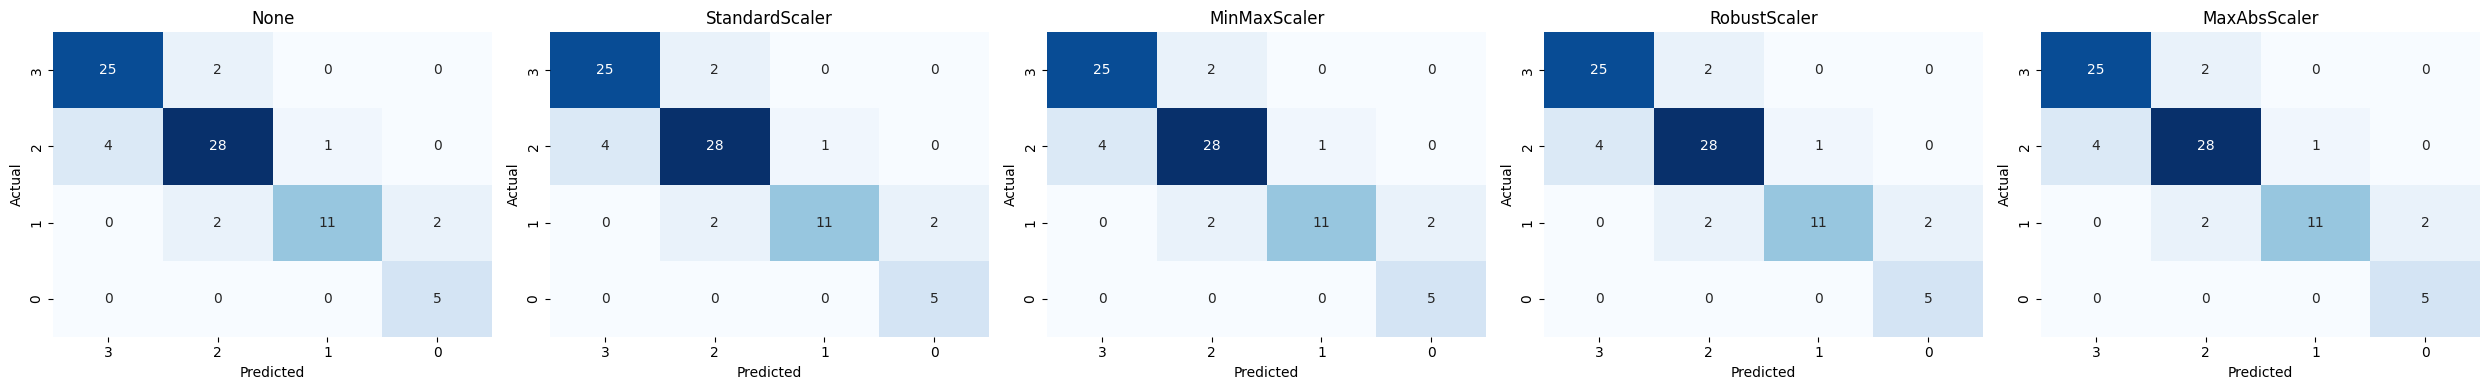

| Name           |   Accuracy |   P_macro |   R_macro |   F1_macro |   P_micro |   R_micro |   F1_micro |   P_weight |   R_weight |   F1_weight |
|:---------------|-----------:|----------:|----------:|-----------:|----------:|----------:|-----------:|-----------:|-----------:|------------:|
| None           |     0.8625 |  0.842005 |  0.876936 |   0.850636 |    0.8625 |    0.8625 |     0.8625 |   0.868404 |     0.8625 |    0.861585 |
| StandardScaler |     0.8625 |  0.842005 |  0.876936 |   0.850636 |    0.8625 |    0.8625 |     0.8625 |   0.868404 |     0.8625 |    0.861585 |
| MinMaxScaler   |     0.8625 |  0.842005 |  0.876936 |   0.850636 |    0.8625 |    0.8625 |     0.8625 |   0.868404 |     0.8625 |    0.861585 |
| RobustScaler   |     0.8625 |  0.842005 |  0.876936 |   0.850636 |    0.8625 |    0.8625 |     0.8625 |   0.868404 |     0.8625 |    0.861585 |
| MaxAbsScaler   |     0.8625 |  0.842005 |  0.876936 |   0.850636 |    0.8625 |    0.8625 |     0.8625 |   0.868404 |     0.8625 |    0.861585 |

In [24]:
xgb_param_grid = {
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'n_estimators': [100, 200, 300],
    'min_child_weight': [1, 3, 5, 10],
    'max_depth': [3, 5, 7],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

XGB_models      = []
best_xgb_models = []
xgb_predictions = {}
feature_train_scaled, feature_test_scaled, label_train, label_test = train_test_scaled_split(features, labels, random_state=3)

for i in range(len(scalers)):
    XGB_models.append(XGBClassifier(eval_metric = 'logloss', random_state = 398))
    grid = GridSearchCV(estimator = XGB_models[i], param_grid = xgb_param_grid, cv = 5, scoring = 'accuracy', n_jobs = -1)
    grid.fit(feature_train_scaled[i], label_train)
    best_xgb_models.append(grid.best_estimator_)
    xgb_predictions[scaler_names[i]] = best_xgb_models[i].predict(feature_test_scaled[i])

evaluate_predictions(label_test, xgb_predictions, label_order = [3, 2, 1, 0])


- ###  Decision Tree from Scratch

In [ ]:
class Node:
	def __init__(self, left = None, right = None, split_feature_idx = None, split_bound = None, value = None):
		self.left = left
		self.right = right
		self.split_feature_idx = split_feature_idx
		self.split_bound = split_bound
		self.value = value

	def is_leaf(self):
		return self.value is not None


class DTClassifier:
	def __init__(self, max_depth = 7):
		self.max_depth = max_depth
		self.root = None

	def fit(self, X, y):
		self.root = self.Create_Tree(X.values, y.values)

	def predict(self, x_test):
		return np.array([self.find_class(row, self.root) for ind, row in x_test.iterrows()])

	def calc_entropy(self, y):
		cnt = np.bincount(y)
		probs = cnt[cnt > 0] / len(y)
		return -np.sum(probs * np.log2(probs + 1e-9))

	def best_split(self, X, y):
		best_gain = None
		best_feature = None 
		best_bound = None
		cur = self.calc_entropy(y)
		for split_feature_idx in range(X.shape[1]):
			split_bounds = np.unique(X[:, split_feature_idx])
			for split_bound in split_bounds:
				Lcondition = X[:, split_feature_idx] <= split_bound
				Rcondition = X[:, split_feature_idx] > split_bound
				if not np.any(Lcondition) or not np.any(Rcondition):
					continue

				Ly, Ry = y[Lcondition], y[Rcondition]
				LEntropy = self.calc_entropy(Ly)
				REntropy = self.calc_entropy(Ry)
				Lprob = len(Ly) / len(y)
				Rprob = 1 - Lprob
				weighted_entropy = Lprob * LEntropy + Rprob * REntropy
				gain = cur - weighted_entropy

				if (best_gain is None) or (gain > best_gain):
					best_feature = split_feature_idx
					best_bound = split_bound
					best_gain = gain
		return best_feature, best_bound

	def Create_Tree(self, X, y, depth = 0):
		if depth >= self.max_depth or np.unique(y).size == 1:
			return Node(value=self.majority_vote(y))
		feature_idx, split_bound = self.best_split(X, y)
		if feature_idx is None:
			return Node(value=self.majority_vote(y))
		Lcondition = X[:, feature_idx] <= split_bound
		Rcondition = X[:, feature_idx] > split_bound
		left = self.Create_Tree(X[Lcondition], y[Lcondition], depth + 1)
		right = self.Create_Tree(X[Rcondition], y[Rcondition], depth + 1)
		return Node(left = left, right = right, split_feature_idx = feature_idx, split_bound = split_bound)

	def find_class(self, x, node):
		if node.is_leaf():
			return node.value
		if x[node.split_feature_idx] <= node.split_bound:
			return self.find_class(x, node.left)
		else:
			return self.find_class(x, node.right)

	def majority_vote(self, y):
		return np.bincount(y).argmax()

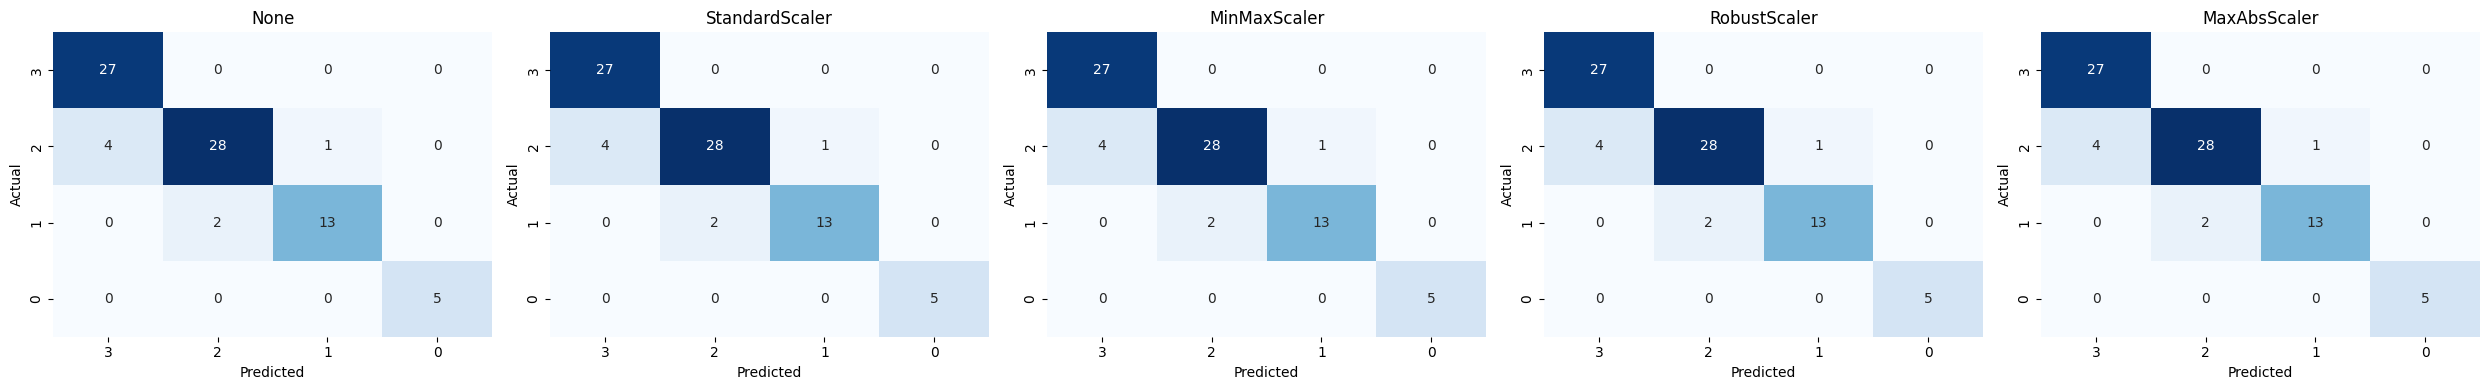

| Name           |   Accuracy |   P_macro |   R_macro |   F1_macro |   P_micro |   R_micro |   F1_micro |   P_weight |   R_weight |   F1_weight |
|:---------------|-----------:|----------:|----------:|-----------:|----------:|----------:|-----------:|-----------:|-----------:|------------:|
| None           |     0.9125 |  0.933218 |  0.928788 |   0.929119 |    0.9125 |    0.9125 |     0.9125 |   0.915559 |     0.9125 |    0.911494 |
| StandardScaler |     0.9125 |  0.933218 |  0.928788 |   0.929119 |    0.9125 |    0.9125 |     0.9125 |   0.915559 |     0.9125 |    0.911494 |
| MinMaxScaler   |     0.9125 |  0.933218 |  0.928788 |   0.929119 |    0.9125 |    0.9125 |     0.9125 |   0.915559 |     0.9125 |    0.911494 |
| RobustScaler   |     0.9125 |  0.933218 |  0.928788 |   0.929119 |    0.9125 |    0.9125 |     0.9125 |   0.915559 |     0.9125 |    0.911494 |
| MaxAbsScaler   |     0.9125 |  0.933218 |  0.928788 |   0.929119 |    0.9125 |    0.9125 |     0.9125 |   0.915559 |     0.9125 |    0.911494 |

C:\Users\ASUS\AppData\Local\Temp\ipykernel_22068\3622304720.py:70: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  if x[node.split_feature_idx] <= node.split_bound:


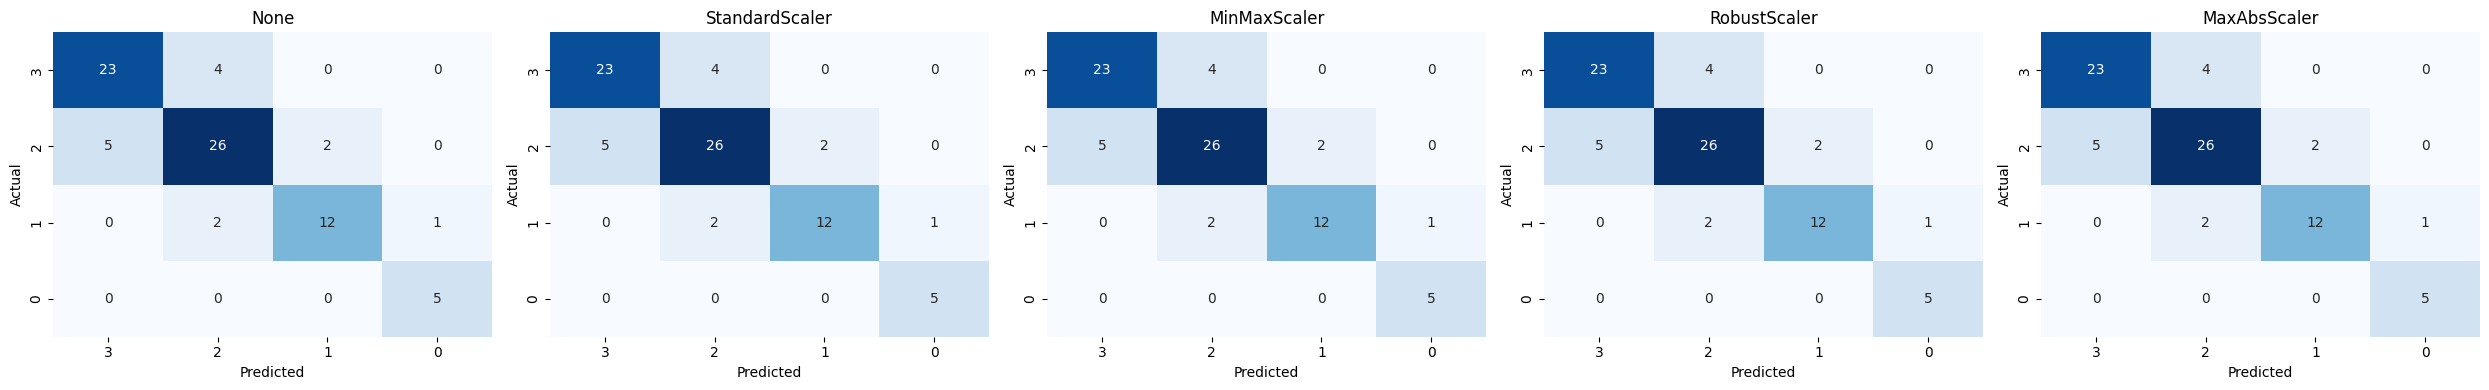

| Name           |   Accuracy |   P_macro |   R_macro |   F1_macro |   P_micro |   R_micro |   F1_micro |   P_weight |   R_weight |   F1_weight |
|:---------------|-----------:|----------:|----------:|-----------:|----------:|----------:|-----------:|-----------:|-----------:|------------:|
| None           |      0.825 |  0.831101 |  0.859933 |    0.84326 |     0.825 |     0.825 |      0.825 |   0.825186 |      0.825 |    0.824263 |
| StandardScaler |      0.825 |  0.831101 |  0.859933 |    0.84326 |     0.825 |     0.825 |      0.825 |   0.825186 |      0.825 |    0.824263 |
| MinMaxScaler   |      0.825 |  0.831101 |  0.859933 |    0.84326 |     0.825 |     0.825 |      0.825 |   0.825186 |      0.825 |    0.824263 |
| RobustScaler   |      0.825 |  0.831101 |  0.859933 |    0.84326 |     0.825 |     0.825 |      0.825 |   0.825186 |      0.825 |    0.824263 |
| MaxAbsScaler   |      0.825 |  0.831101 |  0.859933 |    0.84326 |     0.825 |     0.825 |      0.825 |   0.825186 |      0.825 |    0.824263 |

In [23]:
param_grid = {
    'criterion':           ['gini', 'entropy'],
    'max_depth':           [None, 5, 10, 20],
    'min_samples_split':   [2, 5, 10],
    'min_samples_leaf':    [1, 2, 5],
    'max_features':        [None, 'sqrt', 'log2'],
    'ccp_alpha':           [0.0, 1e-4, 1e-3, 1e-2]
}

DT_models = []
best_models = []
predictions = {}
feature_train_scaled, feature_test_scaled, label_train, label_test = train_test_scaled_split(features, labels, random_state = 3)
for i in range(len(scalers)): 
    DT_models.append(DecisionTreeClassifier(random_state = 398))
    grid = GridSearchCV(DT_models[i], param_grid, cv = 5, scoring = 'accuracy', n_jobs = -1)
    grid.fit(feature_train_scaled[i], label_train)
    best_models.append(grid.best_estimator_)
    predictions[scaler_names[i]] = best_models[i].predict(feature_test_scaled[i])
evaluate_predictions(label_test, predictions, label_order = [3, 2, 1, 0])

my_DT_model = DTClassifier(max_depth = 10)
predictions = {}
for i in range(len(scalers)): 
    my_DT_model.fit(feature_train_scaled[i], label_train)
    predictions[scaler_names[i]] = my_DT_model.predict(feature_test_scaled[i])
evaluate_predictions(label_test, predictions, label_order = [3, 2, 1, 0])


### ❓ **Comparasion Between my Model and Sklearn Model**

>#### *As we can see, the Sklearn model performed better than my custom model. In my opinion, this is because the Sklearn model was fine-tuned using multiple hyperparameters through GridSearchCV, while my model only uses a single hyperparameter — max_depth — which was manually set once. So, this outcome was expected even before comparing the results.*

